# PCA 工具函数学习笔记（附可运行范例）

> 配套文件：`01_鸢尾花PCA_注释版.ipynb`（跑通「实践 1」）
>
> 这份笔记回答一个问题：**原始代码里那些工具函数到底是干什么的、有哪些坑、怎么用才对。**
> 每一章都遵循同一个结构：`它是什么 → 关键参数 → 可运行范例 → 常见坑`。

## 0.1 原始代码里出现过的工具函数对照表

| 函数 / 写法 | 在原始代码里的作用 | 本文档章节 |
| --- | --- | --- |
| `np.mean(x, axis=0)` | 求每个特征的均值（零均值化） | 第 2 章 |
| `np.tile(v, (rows, 1))` | 把均值向量复制成矩阵，用于相减 | 第 3 章 |
| `data - mean_vector`（广播） | 免循环的逐元素相减 | 第 3 章 |
| `np.cov(x, rowvar=0)` | 协方差矩阵 | 第 4 章 |
| `np.linalg.eig(...)` | 特征值 / 特征向量分解 | 第 5 章 |
| `np.argsort(-x)` | 降序排列，取「前 k 大」的下标 | 第 6 章 |
| `np.sort` / `sum` / 累加判断 | `Percentage2n` 里确定要保留几维 | 第 6 章 |
| `np.dot(a, b)` / `np.mat(a) * b` | 矩阵乘法（投影、反投影） | 第 7 章 |
| `np.float32` / `.astype(np.uint8)` | 图像数据转浮点、再转回像素 | 第 8 章 |
| `plt.figure` / `add_subplot` / `scatter` / `legend` / `show` | 画散点图 | 第 9 章 |
| `cv2.imread` / `cvtColor` / `imshow` / `waitKey` / `destroyAllWindows` | 读图、转灰度、显示 | 第 10 章 |

## 0.2 运行环境

```
Python 3.13 / numpy 2.3 / matplotlib 3.11 / opencv-python 5.1 / scikit-learn 1.9
```

> 注意：本文档里的示例基于 **NumPy 2.x**。如果你装的是 1.x，个别「已移除」的结论会不一样
> （比如 `np.mat` 在 1.x 里还能用，只是被标记为废弃）。每一章都会写明版本差异。

In [1]:
%matplotlib inline
# ==================== 0. 环境准备 ====================
import os
import time
import warnings

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import cv2 as cv

warnings.simplefilter("ignore")          # 示例里会故意用一些已废弃写法，屏蔽警告便于阅读

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

np.set_printoptions(precision=4, suppress=True, linewidth=120)
np.random.seed(0)
os.makedirs("images", exist_ok=True)

print("numpy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)
print("opencv     :", cv.__version__)

numpy      : 2.3.3
matplotlib : 3.11.2
opencv     : 5.1.0


# 1. `np.mean`：均值、`axis`、`keepdims`

## 它是什么

`np.mean(x, axis=None, dtype=None, keepdims=False)` = 求和 ÷ 元素个数。

**`axis` 的语义只有一句话：axis=k 表示「沿着第 k 个轴压缩」，即把第 k 维「消掉」。**

| 写法 | 输入形状 | 输出形状 | 含义 |
| --- | --- | --- | --- |
| `x.mean()` | (3, 4) | 标量 | 所有元素的平均 |
| `x.mean(axis=0)` | (3, 4) | (4,) | 沿行方向压缩 → **每列一个均值** ← PCA 用这个 |
| `x.mean(axis=1)` | (3, 4) | (3,) | 沿列方向压缩 → **每行一个均值** |
| `x.mean(axis=0, keepdims=True)` | (3, 4) | (1, 4) | 保留维度，方便直接广播 |

## 为什么 PCA 用 `axis=0`

数据约定成 `(样本数, 特征数) = (150, 4)`，**一个特征就是一列**。
零均值化要求「每个特征减去它自己的均值」，也就是**按列求均值** → `axis=0`。

如果误写成 `axis=1`，就变成「每个样本减去它自己 4 个特征的均值」，
这会把「样本的整体大小」抹掉，完全不是 PCA 要做的事。

## 相关函数

| 函数 | 区别 |
| --- | --- |
| `x.mean()` | 普通均值 |
| `np.nanmean(x)` | 忽略 NaN；普通 `mean` 碰到一个 NaN 整列都变 NaN |
| `np.average(x, weights=w)` | 加权均值 |
| `x.std(axis=0, ddof=1)` | 标准差，分母 n-1（样本）/ n（总体） |
| `x.var(axis=0, ddof=1)` | 方差 = 标准差²，等于协方差矩阵的对角元 |

In [2]:
# ---------- 1.1 axis 的形状规则 ----------
a = np.arange(12).reshape(3, 4)          # 3 行 4 列
print("a =\n", a)
print("a.shape           =", a.shape)
print("a.mean()          =", a.mean(), "           ← 标量")
print("a.mean(axis=0)    =", a.mean(axis=0), "     ← (4,) 每列均值，PCA 用这个")
print("a.mean(axis=1)    =", a.mean(axis=1), "     ← (3,) 每行均值")
print("a.mean(axis=0, keepdims=True).shape =", a.mean(axis=0, keepdims=True).shape, " ← 保留维度便于广播")
print("手算对照 sum/3    :", a.sum(axis=0) / a.shape[0], " 一致:", np.allclose(a.mean(axis=0), a.sum(axis=0) / 3))

# ---------- 1.2 NaN 与加权 ----------
b = np.array([[1.0, 2.0], [3.0, np.nan]])
print("\nb.mean()    =", b.mean(), "   ← 一个 NaN 污染全局")
print("np.nanmean  =", np.nanmean(b), " ← 忽略 NaN")
print("np.average 加权均值（axis=0，权重 [1,1,2]）:", np.average(a, axis=0, weights=[1, 1, 2]))

# ---------- 1.3 在真实数据上：鸢尾花每个特征的均值/标准差 ----------
from sklearn.datasets import load_iris
iris = load_iris()
X = iris.data
mu = X.mean(axis=0)
sd = X.std(axis=0, ddof=1)               # ddof=1：样本标准差（分母 n-1）
print("\n鸢尾花 4 个特征:")
for name, m, s in zip(iris.feature_names, mu, sd):
    print(f"  {name:24s} 均值={m:7.4f}  标准差={s:6.4f}")
print("np.cov 的对角元应等于标准差的平方:", np.allclose(np.diag(np.cov(X, rowvar=0)), sd ** 2))

# ---------- 1.4 一个容易踩的坑：整数数组求均值 ----------
i32 = np.array([1, 2], dtype=np.int32)
print("\nint32 数组求均值 → dtype:", i32.mean().dtype, "（numpy 会自动提升为 float64，不会截断）")

a =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
a.shape           = (3, 4)
a.mean()          = 5.5            ← 标量
a.mean(axis=0)    = [4. 5. 6. 7.]      ← (4,) 每列均值，PCA 用这个
a.mean(axis=1)    = [1.5 5.5 9.5]      ← (3,) 每行均值
a.mean(axis=0, keepdims=True).shape = (1, 4)  ← 保留维度便于广播
手算对照 sum/3    : [4. 5. 6. 7.]  一致: True

b.mean()    = nan    ← 一个 NaN 污染全局
np.nanmean  = 2.0  ← 忽略 NaN
np.average 加权均值（axis=0，权重 [1,1,2]）: [5. 6. 7. 8.]



鸢尾花 4 个特征:
  sepal length (cm)        均值= 5.8433  标准差=0.8281
  sepal width (cm)         均值= 3.0573  标准差=0.4359
  petal length (cm)        均值= 3.7580  标准差=1.7653
  petal width (cm)         均值= 1.1993  标准差=0.7622
np.cov 的对角元应等于标准差的平方: True

int32 数组求均值 → dtype: float64 （numpy 会自动提升为 float64，不会截断）


# 2. `np.tile` 与广播（broadcasting）

## 它是什么

`np.tile(数组, 重复次数)`：把数组**按块复制**成更大的数组。

```python
np.tile(v, 2)        # 一维重复 2 次 → (6,)
np.tile(v, (3, 2))   # 先按行方向 3 次、列方向 2 次 → (3, 6)
np.tile(v, (4, 1))   # 4 行 1 列 → (4, len(v))，每行都是 v 的副本
```

原始代码里：

```python
meanVal = np.tile(meanVal, (rows, 1))    # (4,) → (150, 4)，每行都是同一个均值向量
newdata = dataMat - meanVal              # 逐元素相减
```

## 其实不用 tile —— 广播

NumPy 的广播规则：**从最后一维开始向前对齐，长度为 1 或缺省的维度会被自动「拉伸」。**

`(150, 4) - (4,)` 时，`(4,)` 被当作 `(1, 4)`，再沿第 0 轴拉伸 150 次 → 正好是「每行减同一个向量」。

所以 `data - mean_vector` 与 `data - np.tile(mean_vector, (150, 1))` **结果相同**，
但广播**不实际复制内存**，速度快、内存省。这是 NumPy 最核心的性能技巧之一。

## 常见坑

| 坑 | 现象 |
| --- | --- |
| 形状无法对齐 | `ValueError: operands could not be broadcast together with shapes (4,) (3,)` |
| 误以为广播会改原数组 | 广播产生新数组，原数组不变（要改原数组用 `-=`） |
| 用 `tile` 处理百万行数据 | 会真的复制出 (1000000, 4) 的副本，内存爆炸 |
| 忘记 `keepdims` | `X.mean(axis=1)` 得到 (n,) 无法和 (n, m) 相减，要写 `axis=1, keepdims=True` |

In [3]:
# ---------- 2.1 tile 的三种用法 ----------
v = np.array([1.0, 2.0, 3.0])
print("v                    =", v, v.shape)
print("np.tile(v, 2)        =", np.tile(v, 2))
print("np.tile(v, (3, 1)).shape =", np.tile(v, (3, 1)).shape)
print("np.tile(v, (3, 1)) =\n", np.tile(v, (3, 1)))
print("np.tile(v, (2, 2)) =\n", np.tile(v, (2, 2)))

# ---------- 2.2 原代码写法 vs 广播写法，结果一致 ----------
rng = np.random.default_rng(0)
X = rng.normal(size=(150, 4))
mu = X.mean(axis=0)

tiled = np.tile(mu, (150, 1))            # 真的复制了 150 份
with_tile = X - tiled
with_bc = X - mu                         # 广播，不复制
print("\n两种写法结果一致:", np.allclose(with_tile, with_bc))
print("tile 出来的临时数组占用 :", tiled.nbytes, "字节")
print("广播没有临时数组        :", 0, "字节（按需计算）")

# 数据一大，差别就很明显
big = np.zeros((1_000_000, 4))
print("若对 100 万个样本用 tile:", np.tile(mu, (1_000_000, 1)).nbytes / 1e6, "MB 的额外内存")

# ---------- 2.3 广播规则：从最后一维往前对齐 ----------
print("\n(2,1) + (3,) →", (np.array([[0.], [10.]]) + np.arange(3)).shape, "  # (2,1) 与 (3,) 广播成 (2,3)")
print("结果 =\n", np.array([[0.], [10.]]) + np.arange(3))
try:
    np.arange(4) - np.arange(3)
except ValueError as e:
    print("\n形状不兼容时报错:", e)

# ---------- 2.4 keepdims 的用处 ----------
row_mean = X.mean(axis=1)                        # (150,)   无法直接和 (150,4) 广播
print("\naxis=1 直接相减会报错（(150,4)-(150,) 无法对齐）")
print("改用 keepdims=True:", (X - X.mean(axis=1, keepdims=True)).shape, " ← (150,1) 可以广播")

v                    = [1. 2. 3.] (3,)
np.tile(v, 2)        = [1. 2. 3. 1. 2. 3.]
np.tile(v, (3, 1)).shape = (3, 3)
np.tile(v, (3, 1)) =
 [[1. 2. 3.]
 [1. 2. 3.]
 [1. 2. 3.]]
np.tile(v, (2, 2)) =
 [[1. 2. 3. 1. 2. 3.]
 [1. 2. 3. 1. 2. 3.]]

两种写法结果一致: True
tile 出来的临时数组占用 : 4800 字节
广播没有临时数组        : 0 字节（按需计算）
若对 100 万个样本用 tile: 32.0 MB 的额外内存

(2,1) + (3,) → (2, 3)   # (2,1) 与 (3,) 广播成 (2,3)
结果 =
 [[ 0.  1.  2.]
 [10. 11. 12.]]

形状不兼容时报错: operands could not be broadcast together with shapes (4,) (3,) 

axis=1 直接相减会报错（(150,4)-(150,) 无法对齐）
改用 keepdims=True: (150, 4)  ← (150,1) 可以广播


# 3. `np.cov`：协方差矩阵

## 它是什么

协方差衡量「两个变量是否同向变化」：

$$\mathrm{cov}(x,y)=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar x)(y_i-\bar y)$$

把每对变量都算一遍，就得到协方差矩阵 $C$（4 个特征 → 4×4）：

- 对角元 $C_{ii}$ = 特征 i 的**方差**；
- 非对角元 $C_{ij}$ = 特征 i 与特征 j 的**协方差**；
- 矩阵一定**对称**、**半正定** → 特征值 ≥ 0、特征向量两两正交。

## 关键参数

| 参数 | 含义 | 建议 |
| --- | --- | --- |
| `rowvar=True`（默认） | **每一行**是一个变量 | 数据是 `(特征, 样本)` 时用 |
| `rowvar=False/0` | **每一列**是一个变量 | 数据是 `(样本, 特征)` 时用 ← PCA 的常规约定 |
| `ddof=1`（默认） | 除以 n-1，样本协方差（无偏） | 与 `sklearn` 一致 |
| `bias=True` 或 `ddof=0` | 除以 n，总体协方差 | 只影响整体缩放，**不改变特征向量** |
| `aweights` | 样本权重 | 加权 PCA 时用 |

## `np.cov` vs `np.corrcoef`

| | 协方差 `np.cov` | 相关系数 `np.corrcoef` |
| --- | --- | --- |
| 是否有量纲 | 有（cm²、kg·cm…） | 无（恒在 [-1, 1]） |
| 是否受量纲影响 | **严重** | 不受 |
| PCA 用哪个 | 用协方差（相当于不标准化） | 用相关系数 ≈ 先标准化再做 PCA |

## 为什么要小心「量纲」

如果两个特征的方差相差几个数量级（例如「面积」和「长度」），
协方差矩阵会被方差大的特征主导，第一主成分几乎就等于那个特征本身，
PCA 就退化成「挑出方差最大的列」—— 这时必须先标准化（第 3.4 节的实验会亲眼看到）。

In [4]:
# ---------- 3.1 np.cov 的形状与 rowvar ----------
rng = np.random.default_rng(1)
X = rng.normal(size=(200, 3))
X[:, 1] = X[:, 0] * 2 + rng.normal(scale=0.1, size=200)   # 让第 1、2 个特征强相关

C = np.cov(X, rowvar=0)                 # (200,3) 数据，每一列是一个变量
print("np.cov(X, rowvar=0).shape =", C.shape, " ← 3×3，正是我们要的")
print(C)
print("对称:", np.allclose(C, C.T))
print("rowvar=1 的形状（变量当成 200 个）:", np.cov(X, rowvar=1).shape, "  ← 写反的后果")

# ---------- 3.2 与手算公式对照 ----------
Xc = X - X.mean(axis=0)
manual = Xc.T @ Xc / (X.shape[0] - 1)
print("\n手算 X'ᵀX'/(n-1) 与 np.cov 一致:", np.allclose(C, manual))
print("注意 np.cov 内部会自己减均值，所以对未中心化的 X 直接用也一样:",
      np.allclose(np.cov(X, rowvar=0), C))

# ---------- 3.3 ddof / 相关系数 ----------
C0 = np.cov(X, rowvar=0, ddof=0)
print("\nddof=0 与 ddof=1 的比例（应 = (n-1)/n = %.5f）:" % ((X.shape[0] - 1) / X.shape[0]),
      np.allclose(C0 / C, (X.shape[0] - 1) / X.shape[0]))
print("ddof 不影响特征向量方向，只影响特征值大小")

R = np.corrcoef(X, rowvar=0)
print("\n相关系数矩阵（对角恒为 1，取值 [-1,1]）:\n", R)
print("corrcoef 也可以用来验证「Xc 标准化后做 cov 就是相关矩阵」:",
      np.allclose(np.cov(Xc / Xc.std(axis=0, ddof=1), rowvar=0), R))

# ---------- 3.4 实验：量纲如何「绑架」PCA ----------
print("\n=== 实验：把第 3 个特征放大 100 倍，看主成分怎么变 ===")
from sklearn.datasets import load_iris
iris = load_iris()
A = iris.data.copy()
B = iris.data.copy()
B[:, 3] *= 100                          # 只把「花瓣宽」的单位从 cm 换成 0.01cm

def pc1_loading(M):
    Cm = np.cov(M, rowvar=0)
    w, V = np.linalg.eigh(Cm)
    v = V[:, np.argmax(w)]              # 最大特征值对应的方向
    if v[0] < 0:
        v = -v                          # 统一符号方便比较
    return w[np.argmax(w)], w[np.argmax(w)] / w.sum(), v

l1, r1, v1 = pc1_loading(A)
l2, r2, v2 = pc1_loading(B)
print(f"原始数据     : PC1 特征值={l1:.4f}  贡献率={r1*100:.2f}%  载荷={np.round(v1,3)}")
print(f"第 4 列 ×100 : PC1 特征值={l2:.4f}  贡献率={r2*100:.2f}%  载荷={np.round(v2,3)}")
print("→ 放大后 PC1 的载荷几乎全压在「花瓣宽」上，其余特征的信息被挤掉了。")
print("→ 这时如果先标准化（除以各自标准差），两个方案会得到同一个方向。")

def pc1_loading_std(M):
    Z = (M - M.mean(axis=0)) / M.std(axis=0, ddof=1)
    return pc1_loading(Z)

_, rs1, vs1 = pc1_loading_std(A)
_, rs2, vs2 = pc1_loading_std(B)
print(f"\n标准化后两版 PC1 贡献率: {rs1*100:.2f}% / {rs2*100:.2f}%（一致），载荷也一致:",
      np.allclose(vs1, vs2))

np.cov(X, rowvar=0).shape = (3, 3)  ← 3×3，正是我们要的
[[ 0.9069  1.8166 -0.0798]
 [ 1.8166  3.6504 -0.1674]
 [-0.0798 -0.1674  0.9047]]
对称: True
rowvar=1 的形状（变量当成 200 个）: (200, 200)   ← 写反的后果

手算 X'ᵀX'/(n-1) 与 np.cov 一致: True
注意 np.cov 内部会自己减均值，所以对未中心化的 X 直接用也一样: True

ddof=0 与 ddof=1 的比例（应 = (n-1)/n = 0.99500）: True
ddof 不影响特征向量方向，只影响特征值大小

相关系数矩阵（对角恒为 1，取值 [-1,1]）:
 [[ 1.      0.9984 -0.088 ]
 [ 0.9984  1.     -0.0921]
 [-0.088  -0.0921  1.    ]]
corrcoef 也可以用来验证「Xc 标准化后做 cov 就是相关矩阵」: True

=== 实验：把第 3 个特征放大 100 倍，看主成分怎么变 ===
原始数据     : PC1 特征值=4.2282  贡献率=92.46%  载荷=[ 0.361 -0.085  0.857  0.358]
第 4 列 ×100 : PC1 特征值=5813.4362  贡献率=99.99%  载荷=[ 0.009 -0.002  0.022  1.   ]
→ 放大后 PC1 的载荷几乎全压在「花瓣宽」上，其余特征的信息被挤掉了。
→ 这时如果先标准化（除以各自标准差），两个方案会得到同一个方向。

标准化后两版 PC1 贡献率: 72.96% / 72.96%（一致），载荷也一致: True


# 4. `np.linalg.eig` / `eigh`：特征分解

## 它是什么

求解 $A v = \lambda v$：

- $\lambda$ = **特征值**，表示在 $v$ 这个方向上的「伸缩倍数」；
- $v$ = **特征向量**，表示一个方向。

放到 PCA 里：协方差矩阵 $C$ 的特征向量就是**主成分方向**，
特征值就是**数据在該方向上的方差**（信息量）。

## 返回值：两个最常见的误解

```python
w, v = np.linalg.eig(C)
```

| 返回 | 形状 | 说明 |
| --- | --- | --- |
| `w` | `(n,)` | 特征值，**一维数组**，**顺序任意**（不是从大到小，也不是从小到大） |
| `v` | `(n, n)` | 特征向量，**第 i 列** = `w[i]` 对应的特征向量 |

**误解 1**：以为特征向量按行排 —— 于是写成 `v[:k]` 取到的其实是「前 k 个特征的坐标」，完全错了。正确是 `v[:, idx[:k]]`。

**误解 2**：以为特征值已经排好序 —— 于是 `v[:, :k]` 取到的可能是贡献率只有 0.5% 的方向。必须先 `argsort`。

## `eig` vs `eigh`

| | `np.linalg.eig` | `np.linalg.eigh` |
| --- | --- | --- |
| 适用矩阵 | 任意方阵 | **对称 / Hermitian**矩阵 |
| 数值算法 | 一般 QR 迭代，较慢 | 对称三对角化，更快更稳 |
| 返回顺序 | **任意** | **升序**（特征值从小到大） |
| 返回 dtype | 非对称矩阵可能给复数 | 一定是实数 |
| 协方差矩阵该用哪个 | 能用但没必要 | ✅ 推荐 |

## 两个性质（PCA 的理论地基）

1. **协方差矩阵是对称半正定的**，所以特征值一定 ≥ 0（= 方差，不可能是负的），特征值之和 = 各特征方差之和 = 总方差；
2. **对称矩阵不同特征值对应的特征向量两两正交**（$V^\top V = I$），
   所以主成分之间**互不相关**，这正是「用一组正交方向重新描述数据」的含义。

In [5]:
# ---------- 4.1 小矩阵：手算可验证 ----------
A = np.array([[2.0, 1.0], [1.0, 2.0]])
w, v = np.linalg.eig(A)
print("A =\n", A)
print("特征值 w =", w, "          ← 一维，顺序任意")
print("特征向量 v =\n", v, "  ← 每一**列**是一个特征向量")

# 验证 A v = λ v
for i in range(2):
    print(f"  第 {i} 列: A·v == λ·v ?", np.allclose(A @ v[:, i], w[i] * v[:, i]))
print("每列长度都是 1:", np.linalg.norm(v, axis=0), np.allclose(np.linalg.norm(v, axis=0), 1))
print("正交（VᵀV = I）:", np.allclose(v.T @ v, np.eye(2)))

# ---------- 4.2 eigh：对称矩阵专用，升序返回 ----------
w2, v2 = np.linalg.eigh(A)
print("\neigh 的结果: w =", w2, "（升序；eig 给的是 [3. 1.] 顺序不定）")
print("eig 与 eigh 的特征值集合一致:", np.allclose(np.sort(w), w2))
print("eigh 的特征向量同向（可能差符号）:", np.allclose(np.abs(v), np.abs(v2)))

# ---------- 4.3 非对称矩阵会出现复数（为什么协方差矩阵不会） ----------
B = np.array([[0.0, -1.0], [1.0, 0.0]])       # 90° 旋转矩阵
wb, vb = np.linalg.eig(B)
print("\n旋转矩阵的特征值:", wb, " dtype:", wb.dtype, " ← 复特征值")
print("实部:", np.real(wb), " 虚部:", np.imag(wb))
print("协方差矩阵是对称的，所以特征值永远是实数 → 这就是用 eigh 更省心的原因")

# ---------- 4.4 特征向量符号不唯一：v 和 -v 都对 ----------
lam = w[0]
v0 = v[:, 0]
print("\n验证 v 与 -v 都是特征向量:",
      np.allclose(A @ v0, lam * v0), np.allclose(A @ (-v0), lam * (-v0)))
print("→ 所以自己的 PCA 与 sklearn 的结果可能整体差一个负号，不代表算错")

# ---------- 4.5 重复特征值时：特征向量不唯一（任意正交基都行） ----------
I = np.eye(3)                                  # 特征值全是 1，任意正交方向都是特征向量
print("\n单位阵的特征值:", np.linalg.eigh(I)[0], "→ 方向可以任取")

# ---------- 4.6 在真实协方差矩阵上：特征值之和 = 总方差 ----------
from sklearn.datasets import load_iris
X = load_iris().data
C = np.cov(X, rowvar=0)
vals = np.linalg.eigvalsh(C)                   # 只要特征值（升序）
print("\n鸢尾花协方差矩阵特征值（升序）:", vals)
print("特征值之和 =", vals.sum(), " 各特征方差之和 =", np.diag(C).sum(), " 一致:", np.allclose(vals.sum(), np.diag(C).sum()))
print("特征值全部 ≥ 0（半正定）:", np.all(vals >= -1e-12))

A =
 [[2. 1.]
 [1. 2.]]
特征值 w = [3. 1.]           ← 一维，顺序任意
特征向量 v =
 [[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]   ← 每一**列**是一个特征向量
  第 0 列: A·v == λ·v ? True
  第 1 列: A·v == λ·v ? True
每列长度都是 1: [1. 1.] True
正交（VᵀV = I）: True

eigh 的结果: w = [1. 3.] （升序；eig 给的是 [3. 1.] 顺序不定）
eig 与 eigh 的特征值集合一致: True
eigh 的特征向量同向（可能差符号）: True

旋转矩阵的特征值: [0.+1.j 0.-1.j]  dtype: complex128  ← 复特征值
实部: [0. 0.]  虚部: [ 1. -1.]
协方差矩阵是对称的，所以特征值永远是实数 → 这就是用 eigh 更省心的原因

验证 v 与 -v 都是特征向量: True True
→ 所以自己的 PCA 与 sklearn 的结果可能整体差一个负号，不代表算错

单位阵的特征值: [1. 1. 1.] → 方向可以任取

鸢尾花协方差矩阵特征值（升序）: [0.0238 0.0782 0.2427 4.2282]
特征值之和 = 4.572957046979866  各特征方差之和 = 4.572957046979865  一致: True
特征值全部 ≥ 0（半正定）: True


# 5. `np.argsort`：排序与「取前 k 个」

## 它是什么

`np.argsort(x)` **不返回排好序的数值**，而是返回**能把你排好序的下标**：

```python
x = [3.2, 0.5, 7.1, -1.0]
np.argsort(x)  →  [3, 1, 0, 2]      # 意思：x[3]=-1.0 < x[1]=0.5 < x[0]=3.2 < x[2]=7.1
x[np.argsort(x)]  →  [-1.0, 0.5, 3.2, 7.1]
```

## 和 PCA 的关系

`np.linalg.eig` 不给排序，所以常见套路是：

```python
idx = np.argsort(-eigval)      # 取负号再升序 = 原值降序
topk = idx[:k]                 # 前 k 大的下标
P = eigvec[:, topk]            # 按列取出前 k 个特征向量
```

为什么用 `-eigval` 而不是 `argsort(eigval)[::-1]`？
两者等价；但 `[::-1]` 只是「**倒过来**」，当存在**相等**元素时，
`argsort()[::-1]` 和 `argsort(-x)` 给出的顺序可能不同（稳定性差异）。语义上 `-x` 更直白。

## 相关函数

| 函数 | 返回 | 用途 |
| --- | --- | --- |
| `np.argsort(x)` | 下标 | 需要「排序后的原索引」 |
| `np.sort(x)` | 数值 | 只需要排序后的值 |
| `x[-k:]` / `x[-1:-(k+1):-1]` | 切片 | 取最后 k 个 / 倒序取 k 个 |
| `np.argmax(x)` | 单个下标 | 最大值的下标（PCA 里常用来找第一主成分） |
| `np.argpartition(x, -k)` | 下标 | 只要前 k 大、不需要完整排序时，**比 argsort 快得多**（O(n)） |
| `np.searchsorted(cum, 0.99)` | 下标 | 在**有序**数组里找插入位置 → 一行实现「累计贡献率达到 99% 需要几维」 |
| `np.cumsum(x)` | 累计和 | 累计贡献率 = `cumsum(eigval)/sum` |

## 坑

- `argsort` 默认是**升序**，想要降序必须自己处理（负号或 `[::-1]`）；
- `argsort` 返回的是 `int64` 下标数组，直接拿去索引没问题，但**不能当数值参与运算**；
- 对**含 NaN** 的数组，`argsort` 会把 NaN 排到最后，`argmax` 返回 NaN 的位置 —— 先用 `np.nan_to_num` 或 `nanargmax`。

In [6]:
# ---------- 5.1 argsort 的含义 ----------
s = np.array([3.2, 0.5, 7.1, -1.0])
idx = np.argsort(s)
print("s                =", s)
print("argsort(s)       =", idx, "  ← 下标，不是数值")
print("s[argsort(s)]    =", s[idx], "  ← 升序结果")
print("降序写法 1（负号）:", s[np.argsort(-s)])
print("降序写法 2（反转）:", s[np.argsort(s)[::-1]])
print("最大值的下标 np.argmax:", np.argmax(s), "= 值", s[np.argmax(s)])

# ---------- 5.2 取「前 k 大」的三种写法 ----------
k = 2
print("\n前 2 大的下标 —— argsort 写法     :", np.argsort(s)[-k:][::-1])
print("前 2 大的下标 —— 负号写法        :", np.argsort(-s)[:k])
print("前 2 大的下标 —— argpartition     :", np.argpartition(s, -k)[-k:], "（顺序不保证，只保证是最大的 k 个）")

# 大数据量时 argpartition 明显更快
big = np.random.default_rng(0).normal(size=2_000_000)
t = time.perf_counter(); np.argsort(-big)[:5];        t1 = time.perf_counter() - t
t = time.perf_counter(); np.argpartition(-big, 5)[:5]; t2 = time.perf_counter() - t
print(f"200 万个元素取 top5：argsort {t1*1000:.1f} ms / argpartition {t2*1000:.1f} ms")

# ---------- 5.3 重写原代码 Percentage2n 的逻辑（向量化版） ----------
eig = np.array([4.2282, 0.2427, 0.0782, 0.0238])      # 已排序的特征值
cum_ratio = np.cumsum(eig) / eig.sum()
print("\n单个贡献率:", np.round(eig / eig.sum() * 100, 4))
print("累计贡献率:", np.round(cum_ratio * 100, 4))

def percentage2n_for_loop(eigVals, percentage):
    '''原版 Percentage2n：用循环累加，直到达到 percentage（返回需要的维数）'''
    sortArray = np.sort(eigVals)[::-1]
    total, run, num = sortArray.sum(), 0.0, 0
    for val in sortArray:
        run += val
        num += 1
        if run >= total * percentage:
            return num
    return None                                     # ← p>1 时会返回 None，是个隐藏 bug

for p in (0.90, 0.95, 0.99, 0.999):
    n_loop = percentage2n_for_loop(eig, p)
    n_vec = int(np.searchsorted(cum_ratio, p) + 1)   # 向量化等价写法
    print(f"  保留 {p*100:5.1f}% 信息 → 循环版 {n_loop} 维，searchsorted 版 {n_vec} 维")
print("  p=1.01（非法输入）→ 循环版返回:", percentage2n_for_loop(eig, 1.01))

# ---------- 5.4 在真实特征分解结果上取 top-k ----------
from sklearn.datasets import load_iris
X = load_iris().data
C = np.cov(X, rowvar=0)
w, V = np.linalg.eigh(C)                            # 升序
order_desc = np.argsort(-w)                         # 转成降序下标
print("\neigh 升序特征值:", np.round(w, 4))
print("降序下标       :", order_desc)
print("降序特征值     :", np.round(w[order_desc], 4))
k = 2
P = V[:, order_desc[:k]]
print(f"投影矩阵 P ({P.shape[0]}×{P.shape[1]}):\n", np.round(P, 4))

s                = [ 3.2  0.5  7.1 -1. ]
argsort(s)       = [3 1 0 2]   ← 下标，不是数值
s[argsort(s)]    = [-1.   0.5  3.2  7.1]   ← 升序结果
降序写法 1（负号）: [ 7.1  3.2  0.5 -1. ]
降序写法 2（反转）: [ 7.1  3.2  0.5 -1. ]
最大值的下标 np.argmax: 2 = 值 7.1

前 2 大的下标 —— argsort 写法     : [2 0]
前 2 大的下标 —— 负号写法        : [2 0]
前 2 大的下标 —— argpartition     : [0 2] （顺序不保证，只保证是最大的 k 个）
200 万个元素取 top5：argsort 71.6 ms / argpartition 14.4 ms

单个贡献率: [92.4621  5.3074  1.7101  0.5205]
累计贡献率: [ 92.4621  97.7695  99.4795 100.    ]
  保留  90.0% 信息 → 循环版 1 维，searchsorted 版 1 维
  保留  95.0% 信息 → 循环版 2 维，searchsorted 版 2 维
  保留  99.0% 信息 → 循环版 3 维，searchsorted 版 3 维
  保留  99.9% 信息 → 循环版 4 维，searchsorted 版 4 维
  p=1.01（非法输入）→ 循环版返回: None

eigh 升序特征值: [0.0238 0.0782 0.2427 4.2282]
降序下标       : [3 2 1 0]
降序特征值     : [4.2282 0.2427 0.0782 0.0238]
投影矩阵 P (4×2):
 [[-0.3614  0.6566]
 [ 0.0845  0.7302]
 [-0.8567 -0.1734]
 [-0.3583 -0.0755]]


# 6. 矩阵乘法：`np.dot` / `@` / `np.matmul` / `*` / 已移除的 `np.mat`

这一章是原始代码里**坑最多**的地方，因为原教程写于 NumPy 1.x 时代。

## 四种写法的区别

| 写法 | 语义 | 备注 |
| --- | --- | --- |
| `A @ B` | 矩阵乘法 | **首选**，Python 3.5+ 语法，可读性最好 |
| `np.dot(A, B)` | 矩阵乘法（2 维时与 `@` 等价） | 老代码最常见；高维时语义与 `@` 不同 |
| `np.matmul(A, B)` | 矩阵乘法 | 与 `@` 完全等价 |
| `A * B` | **逐元素相乘**（Hadamard 积） | 不是矩阵乘法！维度必须能广播 |
| `np.mat(A) * B` | 老 `matrix` 类型的矩阵乘法 | **`np.mat` 在 NumPy 2.0 已被移除** |

## `np.mat` / `np.matrix` 为什么被砍掉

`np.matrix` 是 NumPy 早期为「线性代数用户」加的二维专用类型，它有两个致命特点：

1. **`*` 变成矩阵乘法**（与 `ndarray` 语义冲突，同一个符号两种含义）；
2. **永远保持二维**：`np.mat([1,2,3])` 会变成 `(1, 3)`，索引 `m[0]` 返回的是「第一行」而不是「第一个元素」，
   于是 `m[0] * m[1]` 这种写法在某处悄悄变成矩阵乘法，bug 极难查。

NumPy 官方从 1.15 起就建议停止使用，**2.0（2024-06）正式移除 `np.mat` 与 `np.matrix`**。
迁移方式：

```python
# 旧：np.mat(a) * b
a @ b                     # ✅ 推荐
np.dot(a, b)              # ✅
np.asarray(a).dot(b)      # ✅
np.asmatrix(a) * b        # ⚠️ NumPy 2.x 仍保留 asmatrix（内部还是 matrix），但强烈不推荐
```

> 本机实测：`np.asmatrix` 在 2.3 里仍可用（只是受 PendingDeprecationWarning 警告），
> 但 `np.mat` 已经彻底消失。所以原代码 `np.mat(newdata) * fvectormat.T + mean_vector` 会直接报
> `AttributeError: module 'numpy' has no attribute 'mat'`。

## 形状规则（必记）

```
(m, n) @ (n, p) → (m, p)        内维必须相等
(150, 4) @ (4, 2) → (150, 2)    PCA 投影
(150, 2) @ (2, 4) → (150, 4)    PCA 反投影（P 的转置）
```

In [7]:
# ---------- 6.1 三种矩阵乘法写法等价 ----------
A = np.arange(6.).reshape(2, 3)
B = np.arange(6.).reshape(3, 2)
print("A.shape", A.shape, " B.shape", B.shape)
print("A @ B =\n", A @ B)
print("np.dot(A, B) =\n", np.dot(A, B))
print("np.matmul(A, B) =\n", np.matmul(A, B))
print("三者一致:", np.allclose(A @ B, np.dot(A, B)), np.allclose(A @ B, np.matmul(A, B)))

# ---------- 6.2 * 是逐元素乘 ----------
print("\nA * A（逐元素平方）=\n", A * A)
try:
    A * B                                   # (2,3) * (3,2) 无法广播
except ValueError as e:
    print("* 用在形状不同的矩阵上会报错:", str(e)[:80], "...")

# ---------- 6.3 内积：一维数组的 dot 是点积 ----------
u, v = np.array([1., 2., 3.]), np.array([4., 5., 6.])
print("\n一维 dot = 点积:", np.dot(u, v), " 手算:", (u * v).sum())

# ---------- 6.4 np.mat 已移除：亲手验证 + 三种替代 ----------
print("\nhasattr(np, 'mat') =", hasattr(np, "mat"), " ← NumPy 2.x 已彻底移除")
try:
    np.mat(A)
except AttributeError as e:
    print("调用 np.mat 报错:", e)

print("\n替代 1（推荐）A @ B =\n", A @ B)
print("替代 2（老项目风格）np.asmatrix(A) * B =\n", np.asmatrix(A) * B, " ← 能用，但别再写了")
print("替代 3 A.dot(B) =\n", A.dot(B))

# matrix 类型的第二个坑：'永远二维' + '*' 是矩阵乘
m = np.asmatrix([1., 2., 3.])
print("\nnp.asmatrix([1,2,3]).shape =", m.shape, " ← 一维被悄悄升成二维")
print("m[0] 取到的是整行:", m[0], "（若用 ndarray，m[0] 是第一个元素 1.0）")

# ---------- 6.5 原代码那一行的正确写法 ----------
newdata = np.random.rand(150, 2)
fvectormat = np.random.rand(4, 2)
mean_vector = np.random.rand(4)
recon_old = np.asmatrix(newdata) * fvectormat.T + mean_vector    # 老写法（靠 matrix 的 *）
recon_new = newdata @ fvectormat.T + mean_vector                 # 新写法
print("\n老写法与新写法结果一致:", np.allclose(np.asarray(recon_old), recon_new))
print("新写法形状:", recon_new.shape)

# ---------- 6.6 高维时 dot 与 matmul 的区别 ----------
P = np.random.rand(4, 4, 3)                 # 批量：4 个 4×3 矩阵
Q = np.random.rand(4, 3, 2)
print("\n批量 matmul:", (P @ Q).shape, " ← 按批逐对相乘")
print("3 维 dot  :", np.dot(P, Q).shape, " ← 语义不同，容易踩坑，建议一律用 @")

A.shape (2, 3)  B.shape (3, 2)
A @ B =
 [[10. 13.]
 [28. 40.]]
np.dot(A, B) =
 [[10. 13.]
 [28. 40.]]
np.matmul(A, B) =
 [[10. 13.]
 [28. 40.]]
三者一致: True True

A * A（逐元素平方）=
 [[ 0.  1.  4.]
 [ 9. 16. 25.]]
* 用在形状不同的矩阵上会报错: operands could not be broadcast together with shapes (2,3) (3,2)  ...

一维 dot = 点积: 32.0  手算: 32.0

hasattr(np, 'mat') = False  ← NumPy 2.x 已彻底移除
调用 np.mat 报错: `np.mat` was removed in the NumPy 2.0 release. Use `np.asmatrix` instead.

替代 1（推荐）A @ B =
 [[10. 13.]
 [28. 40.]]
替代 2（老项目风格）np.asmatrix(A) * B =
 [[10. 13.]
 [28. 40.]]  ← 能用，但别再写了
替代 3 A.dot(B) =
 [[10. 13.]
 [28. 40.]]

np.asmatrix([1,2,3]).shape = (1, 3)  ← 一维被悄悄升成二维
m[0] 取到的是整行: [[1. 2. 3.]] （若用 ndarray，m[0] 是第一个元素 1.0）

老写法与新写法结果一致: True
新写法形状: (150, 4)

批量 matmul: (4, 4, 2)  ← 按批逐对相乘
3 维 dot  : (4, 4, 4, 2)  ← 语义不同，容易踩坑，建议一律用 @


# 7. `dtype` 与精度：`float32` / `astype` / `uint8` 溢出

原始图像代码里有这几句：

```python
dataMat = np.float32(np.mat(data))       # 转 float32
reconImage = reconImage.astype(np.uint8) # 转回像素
```

## 为什么处理图像要用浮点

- 图像存成 `uint8`（0~255 整数）**省内存**；
- 但 PCA 里要做减法、乘浮点特征向量，`uint8` 会**截断 / 回绕**（0 减 250 得到 6，不是 -250）；
- 所以算法阶段一律转 `float32`（图像够用、省一半内存）或 `float64`（更精确）。

## 为什么 `astype(np.uint8)` 很危险

`astype` 是 **C 语言式的截断/回绕**，不做范围检查：

| 输入 | `.astype(np.uint8)` | 正确做法 |
| --- | --- | --- |
| `-3.7` | `253`（回绕！） | 先 `np.clip(x, 0, 255)` → `0` |
| `260.4` | `4`（回绕！） | 先 `np.clip` → `255` |
| `128.5` | `128`（截断，不是四舍五入） | `np.rint` 再转 |

安全转换模板：

```python
out = np.clip(np.rint(x), 0, 255).astype(np.uint8)
```

## 精度常识

- `np.float32`：约 7 位有效数字，`(1000,1000)` 占 4 MB；
- `np.float64`：约 16 位有效数字，同样数据占 8 MB；
- 浮点比较**永远不要用 `==`**，用 `np.allclose(a, b)` 或 `np.isclose`（因为 `0.1+0.2 != 0.3`）。

In [8]:
# ---------- 7.1 float32 vs float64 ----------
a32 = np.zeros((1000, 1000), dtype=np.float32)
a64 = np.zeros((1000, 1000), dtype=np.float64)
print("1000×1000 float32:", a32.nbytes / 1e6, "MB   float64:", a64.nbytes / 1e6, "MB")
print("float32 有效位数约:", np.finfo(np.float32).nmant, "位尾数 → 约 7 位十进制有效数字")
print("float32 能表示的最大值:", np.finfo(np.float32).max)
print("1e20 存进 float32:", np.float32(1e20), "（精度已严重丢失）")

# ---------- 7.2 uint8 溢出：图像处理最经典的坑 ----------
u = np.array([0, 250], dtype=np.uint8)
print("\nu =", u)
print("u[0] - u[1] =", u[0] - u[1], " ← 期望 -250，实际回绕成 6")
print("(-u[1]).astype(np.uint8) =", (-u[1]).astype(np.uint8), " ← 又是 6（256-250）")
print("正确做法：先转浮点再算:", np.float32(u[0]) - np.float32(u[1]))
print("或者用 cv2.subtract（uint8 图像上会饱和到 0）:",
      cv.subtract(np.array([[0]], np.uint8), np.array([[250]], np.uint8))[0, 0])

# ---------- 7.3 astype 的截断/回绕 ----------
x = np.array([-3.7, 260.4, 128.5, 127.9])
print("\nx =", x)
print("x.astype(np.uint8)        =", x.astype(np.uint8), " ← 负数/超范围回绕，小数截断")
print("安全转换 clip+rint+astype  =", np.clip(np.rint(x), 0, 255).astype(np.uint8))

# ---------- 7.4 浮点比较 ----------
print("\n0.1 + 0.2 =", 0.1 + 0.2, " == 0.3 ?", 0.1 + 0.2 == 0.3)
print("np.isclose(0.1+0.2, 0.3) =", np.isclose(0.1 + 0.2, 0.3), " ← 比较浮点请用 isclose/allclose")
print("默认容差 rtol=1e-05（相对）、atol=1e-08（绝对），可用 np.allclose(a, b, rtol=..., atol=...) 调整")

# ---------- 7.5 图像 PCA 里的标准数据流 ----------
from sklearn.datasets import load_sample_image
img = load_sample_image("china.jpg")                   # uint8 (427,640,3)
gray = cv.cvtColor(img, cv.COLOR_RGB2GRAY).astype(np.float32)
print("\n原图 dtype:", img.dtype, " 灰度 float32 dtype:", gray.dtype, " 形状:", gray.shape)
print("→ 算法阶段用 float32；显示/保存前再 clip + astype(uint8) 变回像素")

1000×1000 float32: 4.0 MB   float64: 8.0 MB
float32 有效位数约: 23 位尾数 → 约 7 位十进制有效数字
float32 能表示的最大值: 3.4028235e+38
1e20 存进 float32: 1e+20 （精度已严重丢失）

u = [  0 250]
u[0] - u[1] = 6  ← 期望 -250，实际回绕成 6
(-u[1]).astype(np.uint8) = 6  ← 又是 6（256-250）
正确做法：先转浮点再算: -250.0
或者用 cv2.subtract（uint8 图像上会饱和到 0）: 0

x = [ -3.7 260.4 128.5 127.9]
x.astype(np.uint8)        = [253   4 128 127]  ← 负数/超范围回绕，小数截断
安全转换 clip+rint+astype  = [  0 255 128 128]

0.1 + 0.2 = 0.30000000000000004  == 0.3 ? False
np.isclose(0.1+0.2, 0.3) = True  ← 比较浮点请用 isclose/allclose
默认容差 rtol=1e-05（相对）、atol=1e-08（绝对），可用 np.allclose(a, b, rtol=..., atol=...) 调整

原图 dtype: uint8  灰度 float32 dtype: float32  形状: (427, 640)
→ 算法阶段用 float32；显示/保存前再 clip + astype(uint8) 变回像素


# 8. matplotlib 基础：把数据画出来

原始代码的画图函数只用了 5 个 API，但每个都有坑。

## 5 个 API 的语义

| API | 作用 | 常见用法 |
| --- | --- | --- |
| `plt.figure(figsize=(w,h))` | 新建一张画布 | `figsize` 单位是英寸，配合 `dpi` 决定像素 |
| `fig.add_subplot(1,2,1)` | 在画布上切出子图 | 三位数字 = 行数、列数、第几个（从 1 开始） |
| `ax.scatter(x, y, ...)` | 画散点 | `s` 点面积、`c` 颜色（可传数组按类别上色）、`marker` 形状 |
| `plt.legend()` / `ax.legend()` | 显示图例 | 要有 `label=` 才会显示；`loc` 调位置 |
| `plt.show()` | 渲染显示 | 在 Jupyter 里由 inline 后端负责输出到 cell 下方 |

## 中文字体（Windows）

```python
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False     # 否则负号是方块
```

## 另外 4 个高频 API

| API | 用途 |
| --- | --- |
| `fig, axes = plt.subplots(2, 2, figsize=...)` | 一次建好网格子图，`axes` 是数组，比 `add_subplot` 更好用 |
| `ax.set_xlabel/ylabel/title` | 轴标签、标题 |
| `ax.set_xlim/ylim` | 手动控制坐标范围（对比不同图时很重要） |
| `fig.savefig(path, dpi=150, bbox_inches="tight")` | 保存图片，`bbox_inches="tight"` 防止标签被裁掉 |
| `ax1.twinx()` | 双 y 轴（例如「误差曲线 + 保留比例曲线」） |

## 坑

| 坑 | 现象 | 解决 |
| --- | --- | --- |
| 中文变方块 | 图里全是 `□□□` | 设置 `font.sans-serif` |
| 负号变方块 | `-1` 显示成 `□1` | `axes.unicode_minus = False` |
| 图不显示 | cell 里没有输出 | 加 `%matplotlib inline`；或调用 `plt.show()` |
| 内存泄漏 | 循环里反复 `plt.figure()` 不关，几百张图后卡死 | `plt.close(fig)` |
| 图例不出现 | 忘了 `label=` | scatter 时给 `label="xxx"` |
| 保存的图是空白 | `savefig` 写在 `show()` 之后（inline 后端已消费掉） | `savefig` 要在 `show()` 之前 |

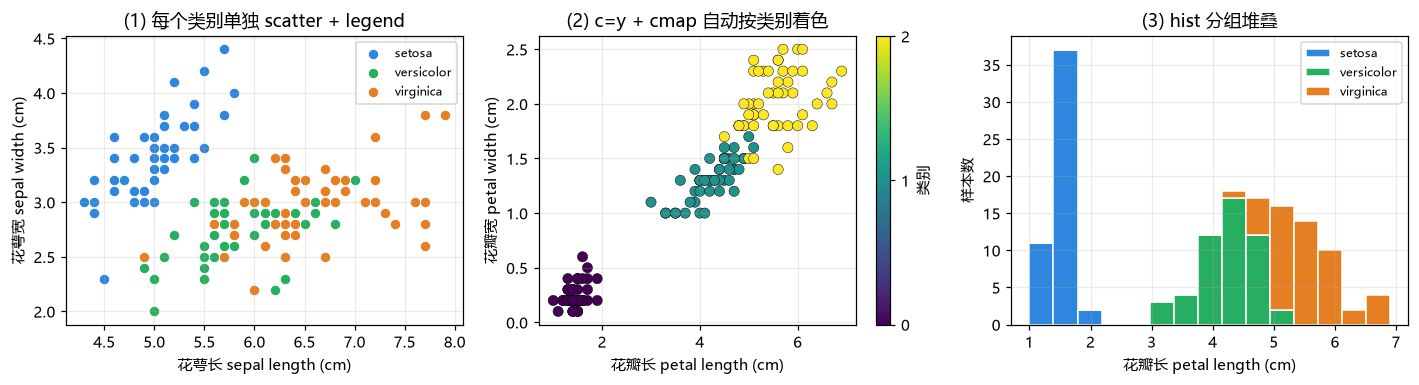

已保存 images/nb2_01_matplotlib_basics.png


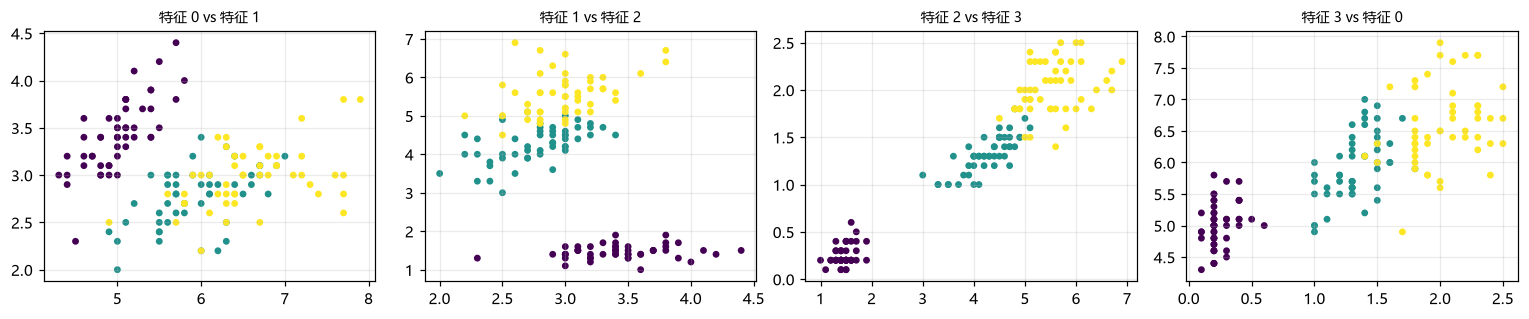

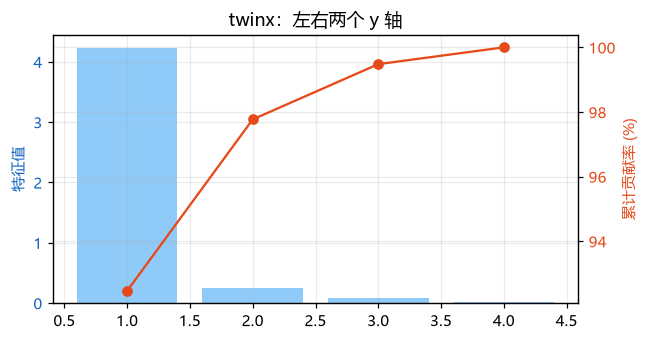

In [9]:
# ---------- 8.1 figure + add_subplot：三图并排 ----------
from sklearn.datasets import load_iris
iris = load_iris()
X, y = iris.data, iris.target
colors = ["#2E86DE", "#27AE60", "#E67E22"]
names = ["setosa", "versicolor", "virginica"]

fig = plt.figure(figsize=(13, 3.6))
ax1 = fig.add_subplot(1, 3, 1)         # 1 行 3 列，第 1 个
ax2 = fig.add_subplot(1, 3, 2)
ax3 = fig.add_subplot(1, 3, 3)

# scatter 的关键参数：x, y, s=面积, c=颜色, marker=形状, alpha=透明度, label=图例文字
for c in range(3):
    m = y == c
    ax1.scatter(X[m, 0], X[m, 1], s=45, c=colors[c], marker="o",
                edgecolors="white", linewidths=0.5, label=names[c])
ax1.set_xlabel("花萼长 sepal length (cm)"); ax1.set_ylabel("花萼宽 sepal width (cm)")
ax1.set_title("(1) 每个类别单独 scatter + legend")
ax1.legend(fontsize=8, loc="upper right")

# 一次 scatter + c 传类别数组 + cmap：更省事
sc = ax2.scatter(X[:, 2], X[:, 3], s=45, c=y, cmap="viridis", edgecolors="k", linewidths=0.3)
ax2.set_xlabel("花瓣长 petal length (cm)"); ax2.set_ylabel("花瓣宽 petal width (cm)")
ax2.set_title("(2) c=y + cmap 自动按类别着色")
fig.colorbar(sc, ax=ax2, ticks=[0, 1, 2], label="类别")

# 只画一个特征分布：直方图
ax3.hist([X[y == c, 2] for c in range(3)], bins=15, stacked=True,
         color=colors, label=names, edgecolor="white")
ax3.set_xlabel("花瓣长 petal length (cm)"); ax3.set_ylabel("样本数")
ax3.set_title("(3) hist 分组堆叠")
ax3.legend(fontsize=8)

plt.tight_layout()
plt.savefig("images/nb2_01_matplotlib_basics.png", dpi=140, bbox_inches="tight")
plt.show()                              # savefig 要在 show 之前
print("已保存 images/nb2_01_matplotlib_basics.png")

# ---------- 8.2 subplots 的更省事写法 ----------
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for j, ax in enumerate(axes):           # axes 是 ndarray，可以直接循环
    ax.scatter(X[:, j], X[:, (j + 1) % 4], s=12, c=y, cmap="viridis")
    ax.set_title(f"特征 {j} vs 特征 {(j+1) % 4}", fontsize=9)
plt.tight_layout()
plt.show()

# ---------- 8.3 双 y 轴（twinx）：一个图里画两种量纲 ----------
vals = np.array([4.2282, 0.2427, 0.0782, 0.0238])
ratio = vals / vals.sum()
ks = np.arange(1, 5)
fig, ax1 = plt.subplots(figsize=(6, 3.2))
ax1.bar(ks, vals, color="#90CAF9", label="特征值（左轴）")
ax1.set_ylabel("特征值", color="#1565C0")
ax1.tick_params(axis="y", labelcolor="#1565C0")
ax2 = ax1.twinx()
ax2.plot(ks, np.cumsum(ratio) * 100, "o-", color="#E64A19", label="累计贡献率 %（右轴）")
ax2.set_ylabel("累计贡献率 (%)", color="#E64A19")
ax2.tick_params(axis="y", labelcolor="#E64A19")
ax1.set_title("twinx：左右两个 y 轴")
plt.tight_layout()
plt.show()

# 9. OpenCV：读图、转灰度、显示

原始图像代码用的是最朴素的 4 个 API：

```python
image = cv.imread('banana.jpg')                      # 读图
image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)        # 转灰度
cv.imshow('test', reconImage); cv.waitKey(0); cv.destroyAllWindows()   # 弹窗显示
```

## 4 个 API + 3 个大坑

| API | 作用 | 坑 |
| --- | --- | --- |
| `cv.imread(path, flags)` | 读图，返回 **BGR** 顺序的 `uint8` 数组 | ① 路径写错/文件不存在时**返回 `None`，不报错**；② 中文路径在 OpenCV 4.x 及以前的 Windows 版会失败（返回 `None`），5.x 起通常可用 —— 但为了兼容，建议统一写 `cv.imdecode(np.fromfile(path, np.uint8), 1)` |
| `cv.cvtColor(img, code)` | 颜色空间转换 | `cv.COLOR_BGR2GRAY`（转灰度）、`cv.COLOR_BGR2RGB`（给 matplotlib 用） |
| `cv.imshow(name, img)` | 弹窗显示 | **在 Jupyter 里会卡住甚至让内核崩溃**（需要 GUI 窗口事件循环），notebook 里请用 matplotlib 显示 |
| `cv.waitKey(0)` / `cv.destroyAllWindows()` | 等待按键 / 关闭窗口 | 只在脚本 + GUI 环境下有意义；notebook 里不要用 |
| `cv.imwrite(path, img)` | 写图 | 同样不支持中文路径，要配 `cv.imencode` + `tofile` |

## BGR vs RGB：最经典的「颜色反了」

- OpenCV 内部约定 **BGR**；
- matplotlib / PIL 约定 **RGB**；
- 所以 `plt.imshow(cv.imread(...))` 会红蓝互换，需要先 `cv.cvtColor(img, cv.COLOR_BGR2RGB)`。

## 本机环境注意

`opencv-python` 可以正常 `import cv2`；但如果服务器没有图形界面，
`cv.imshow` 会直接抛错（`cv2.error: ... The function is not implemented`）。所以本笔记全部用 matplotlib 显示。

读取不存在的文件 → None   is None: True   ← 不抛异常！

cv.imread 返回 shape: (427, 640, 3)  dtype: uint8  ← (高, 宽, 3)，注意不是 (宽, 高)

cv.imwrite 写中文路径是否成功: True  文件是否存在: True
cv.imread 读中文路径得到: (427, 640, 3) （None = 失败，老版本 OpenCV 在 Windows 上是这样）
通用绕过办法：imdecode + np.fromfile → (427, 640, 3)
（本机实测：OpenCV 5.1.0 已支持 UTF-8 路径，但写兼容代码时建议始终用 imdecode 兜底）

灰度图 shape: (427, 640)  dtype: uint8  取值范围: (np.uint8(0), np.uint8(255))


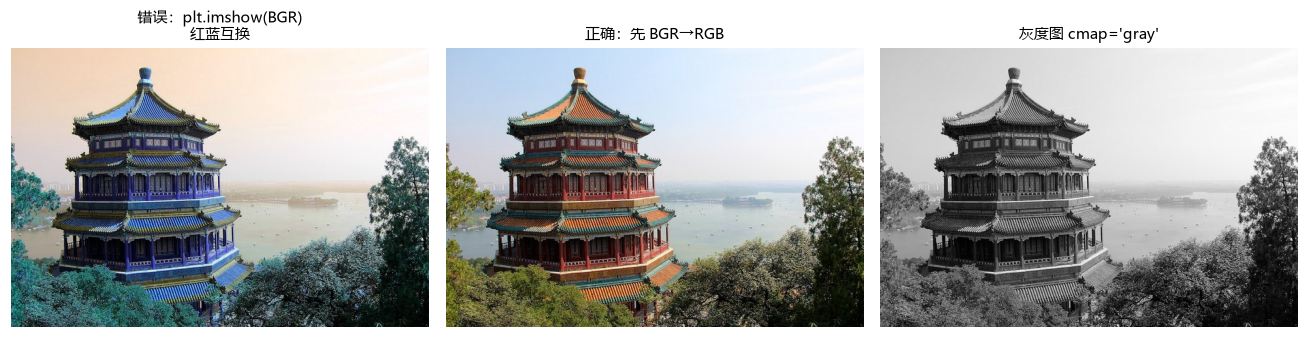

已保存 images/nb2_02_bgr_rgb.png
cv.imshow / cv.waitKey / cv.destroyAllWindows 是「GUI 窗口」API：
  - 脚本 + 桌面环境：imshow 开窗 → waitKey(0) 阻塞等你按键 → destroyAllWindows 关闭
  - Jupyter：没有 GUI 事件循环，轻则卡死，重则内核崩溃（本笔记不执行这三句）
  notebook 里的等价做法：plt.imshow(...) + plt.show()


In [10]:
# ---------- 9.1 imread 的三个坑 ----------
img_none = cv.imread("这个文件不存在.jpg")
print("读取不存在的文件 →", img_none, "  is None:", img_none is None, "  ← 不抛异常！")

# 用 sklearn 自带的示例图造一个真实文件（原代码用的 banana.jpg 本仓库没有）
from sklearn.datasets import load_sample_image
rgb = load_sample_image("china.jpg")                     # (427,640,3) uint8, RGB 顺序
cv.imwrite("images/_demo_bgr.jpg", cv.cvtColor(rgb, cv.COLOR_RGB2BGR))
img = cv.imread("images/_demo_bgr.jpg")
print("\ncv.imread 返回 shape:", img.shape, " dtype:", img.dtype, " ← (高, 宽, 3)，注意不是 (宽, 高)")

# 中文路径：老版本 OpenCV（4.x 及以前）在 Windows 上会读失败返回 None
zh_path = os.path.join("images", "中文路径测试.jpg")
try:
    ok_write = bool(cv.imwrite(zh_path, img))
except Exception as e:                       # noqa: BLE001
    ok_write = False
    print("cv.imwrite 直接抛错:", e)
print("\ncv.imwrite 写中文路径是否成功:", ok_write, " 文件是否存在:", os.path.exists(zh_path))
zh_read = cv.imread(zh_path)
print("cv.imread 读中文路径得到:", None if zh_read is None else zh_read.shape,
      "（None = 失败，老版本 OpenCV 在 Windows 上是这样）")
if os.path.exists(zh_path):
    print("通用绕过办法：imdecode + np.fromfile →",
          cv.imdecode(np.fromfile(zh_path, dtype=np.uint8), cv.IMREAD_COLOR).shape)
else:
    ok_enc, buf = cv.imencode(".jpg", img)   # 先编码到内存
    buf.tofile(zh_path)                      # 再用 numpy 自己写文件（支持中文路径）
    print("改用 imencode + tofile 写中文路径 → 文件已存在:", os.path.exists(zh_path))
    print("读回：imdecode + np.fromfile →",
          cv.imdecode(np.fromfile(zh_path, dtype=np.uint8), cv.IMREAD_COLOR).shape)
print("（本机实测：OpenCV %s 已支持 UTF-8 路径，但写兼容代码时建议始终用 imdecode 兜底）" % cv.__version__)

# ---------- 9.2 灰度化 ----------
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
print("\n灰度图 shape:", gray.shape, " dtype:", gray.dtype, " 取值范围:", (gray.min(), gray.max()))

# ---------- 9.3 BGR / RGB 反色演示 + 用 matplotlib 显示 ----------
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].imshow(img)                                     # 直接把 BGR 交给 matplotlib
axes[0].set_title("错误：plt.imshow(BGR)\n红蓝互换", fontsize=10)
axes[1].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
axes[1].set_title("正确：先 BGR→RGB", fontsize=10)
axes[2].imshow(gray, cmap="gray")
axes[2].set_title("灰度图 cmap='gray'", fontsize=10)
for ax in axes:
    ax.axis("off")                                      # 关掉坐标刻度
plt.tight_layout()
plt.savefig("images/nb2_02_bgr_rgb.png", dpi=140, bbox_inches="tight")
plt.show()
print("已保存 images/nb2_02_bgr_rgb.png")

# ---------- 9.4 cv.imshow 在 notebook 里不能用 ----------
print("cv.imshow / cv.waitKey / cv.destroyAllWindows 是「GUI 窗口」API：")
print("  - 脚本 + 桌面环境：imshow 开窗 → waitKey(0) 阻塞等你按键 → destroyAllWindows 关闭")
print("  - Jupyter：没有 GUI 事件循环，轻则卡死，重则内核崩溃（本笔记不执行这三句）")
print("  notebook 里的等价做法：plt.imshow(...) + plt.show()")

# 10. 综合范例 A：把前面所有函数串起来，手算一个 4 维 PCA

这一节用一个小矩阵（**5 个样本 × 4 个特征**）把全流程走一遍，
每一步都同时给出「函数写法」和「手算结果」，方便逐项核对。

In [11]:
np.set_printoptions(precision=4, suppress=True, linewidth=140)

# 造一个 5×4 的小数据（故意让第 2 列和第 4 列高度相关）
D = np.array([
    [2.5, 2.4, 0.5, 0.6],
    [0.5, 0.7, 1.2, 1.3],
    [2.2, 2.9, 1.6, 1.4],
    [1.9, 2.2, 0.9, 1.1],
    [3.1, 3.0, 2.3, 2.5],
])
n, m = D.shape
print("原始数据 D（%d×%d）:\n" % (n, m), D)

# ① 零均值化
mu = D.mean(axis=0)
Dc = D - mu
print("\n① 均值 mu =", mu)
print("   中心化后每列均值 =", Dc.mean(axis=0), " (≈0，验证:", np.allclose(Dc.mean(axis=0), 0), ")")

# ② 协方差矩阵
C = np.cov(Dc, rowvar=0)
C_manual = Dc.T @ Dc / (n - 1)
print("\n② 协方差矩阵 C:\n", C)
print("   与手算一致:", np.allclose(C, C_manual))

# ③ 特征分解（对称 → 用 eigh）
w, V = np.linalg.eigh(C)
print("\n③ 特征值（升序）:", w)
print("   特征向量（列）:\n", V)

# ④ 排序 + 贡献率
order = np.argsort(-w)
w, V = w[order], V[:, order]
print("\n④ 降序特征值:", w)
print("   贡献率    :", np.round(w / w.sum() * 100, 2), "%")
print("   累计贡献率:", np.round(np.cumsum(w) / w.sum() * 100, 2), "%")

# ⑤ 取前 k=2 个主成分
k = 2
P = V[:, :k]
print("\n⑤ 投影矩阵 P (%d×%d):\n" % P.shape, P)

# ⑥ 投影
Y = Dc @ P
print("\n⑥ 降维结果 Y = Dc·P（%d×%d）:\n" % Y.shape, Y)
print("   验证：Y 的方差 = 特征值:", np.allclose(Y.var(axis=0, ddof=1), w[:k]), Y.var(axis=0, ddof=1))
print("   协方差矩阵为对角阵:", np.allclose(np.cov(Y, rowvar=0), np.diag(w[:k])))

# ⑦ 反投影 / 重构
Dhat = Y @ P.T + mu
print("\n⑦ 重构 D̂ = Y·Pᵀ + μ:\n", Dhat)
err = D - Dhat
print("   每个样本的重构误差(欧氏距离):", np.round(np.linalg.norm(err, axis=1), 4))
print("   保留的信息比例 =", f"{1 - (err**2).sum() / ((D - Dc.mean(axis=0))**2).sum():.6f}")

# ⑧ 与 sklearn 对照
from sklearn.decomposition import PCA as SkPCA
sk = SkPCA(n_components=2).fit(D)
print("\n⑧ sklearn 解释方差:", np.round(sk.explained_variance_, 4), " 手算:", np.round(w[:2], 4),
      " 一致:", np.allclose(sk.explained_variance_, w[:2]))

原始数据 D（5×4）:
 [[2.5 2.4 0.5 0.6]
 [0.5 0.7 1.2 1.3]
 [2.2 2.9 1.6 1.4]
 [1.9 2.2 0.9 1.1]
 [3.1 3.  2.3 2.5]]

① 均值 mu = [2.04 2.24 1.3  1.38]
   中心化后每列均值 = [ 0.  0. -0. -0.]  (≈0，验证: True )

② 协方差矩阵 C:
 [[0.938  0.8405 0.2375 0.2485]
 [0.8405 0.853  0.25   0.2185]
 [0.2375 0.25   0.475  0.4675]
 [0.2485 0.2185 0.4675 0.487 ]]
   与手算一致: True

③ 特征值（升序）: [0.0041 0.0632 0.7238 1.9619]
   特征向量（列）:
 [[-0.2672 -0.6343 -0.3115 -0.6551]
 [ 0.2931  0.6636 -0.2906 -0.6239]
 [-0.6571  0.2808  0.6302 -0.3036]
 [ 0.641  -0.28    0.6491 -0.299 ]]

④ 降序特征值: [1.9619 0.7238 0.0632 0.0041]
   贡献率    : [71.26 26.29  2.3   0.15] %
   累计贡献率: [ 71.26  97.56  99.85 100.  ] %

⑤ 投影矩阵 P (4×2):
 [[-0.6551 -0.3115]
 [-0.6239 -0.2906]
 [-0.3036  0.6302]
 [-0.299   0.6491]]

⑥ 降维结果 Y = Dc·P（5×2）:
 [[ 0.0749 -1.2003]
 [ 2.024   0.8123]
 [-0.6136 -0.0396]
 [ 0.3218 -0.3786]
 [-1.8071  0.8061]]
   验证：Y 的方差 = 特征值: True [1.9619 0.7238]
   协方差矩阵为对角阵: True

⑦ 重构 D̂ = Y·Pᵀ + μ:
 [[2.3649 2.5421 0.5208 0.5785]
 [0.461  0.

# 11. 综合范例 B：用 PCA 压缩图片（原代码「实践 2」的注释版 + 扩展实验）

## 原理

一张 `427 × 640` 的灰度图，可以看成「640 个特征、427 个样本」的数据集：
每一**列**是一个「像素位置」，每个样本是一个「像素位置在 427 行上的取值」。

对它做 PCA，就相当于说：**这 640 个列向量并不独立，它们大致落在少数几个方向上**。
只保留前 k 个主成分再反投影，就能用 $427k + 640k$ 个数字替代 $427\times640$ 个数字，
从而「压缩」，代价是画面变模糊。

## 原代码的 6 个函数

| 函数 | 作用 | 注释要点 |
| --- | --- | --- |
| `Z_centered` | 中心化 | 用 `np.tile` 复制均值向量（本可以广播） |
| `Percentage2n` | 由「要保留多少比例的信息」反推 k | 循环累加；**p>1 时返回 None**，是个隐藏 bug |
| `EigDV` | 特征分解 + 取前 k 个 | 用 `eig` 而非 `eigh`；`np.argsort` 后 `[-1:-(k+1):-1]` |
| `getlowDataMat` | 投影 | `DataMat * K_eigenVector`（matrix 类型） |
| `Reconstruction` | 反投影 | `lowDataMat * K_eigenVector.T + meanVal` |
| `PCA` | 串联 | `np.float32(np.mat(data))` ← **`np.mat` 已移除** |

## 本 repo 的图片

原代码读的是 `banana.jpg`（本仓库未附带）。这里做**优雅降级**：
存在 `banana.jpg` 就用它，否则用 scikit-learn 自带的示例图 `china.jpg`，
两者在数学上完全等价（都是 `uint8` 灰度矩阵）。

未找到 banana.jpg → 改用 scikit-learn 自带示例图 china.jpg
降维前的「数据列数」= 640（每个像素位置是一个特征），样本数 = 427
原图矩阵形状: (427, 640)  dtype: uint8
（原代码在这里 print(image) 会刷出 427 行数字，本项目只打印前 3 行）
[[196 196 196 196 196 196 196 196]
 [194 195 195 196 196 196 197 198]
 [196 196 196 196 196 196 197 197]]
----------------------------------------


保留 99% 的信息需要的维数 = 171
重构后矩阵形状: (427, 640)  dtype: uint8
保留的主成分个数 k = 171  压缩后需要的数字个数 = 73017


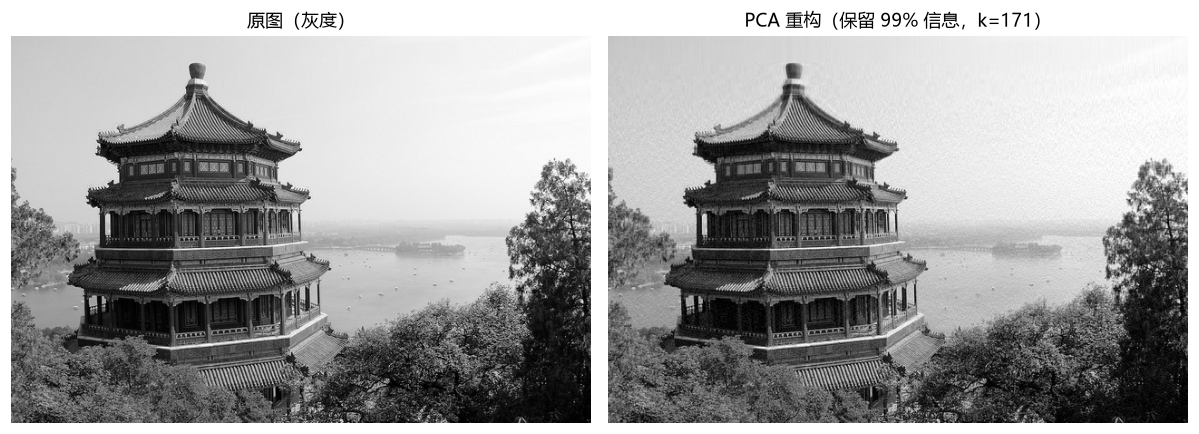

已保存 images/nb2_03_image_pca_99.png


In [12]:
# ============================================================================
# 11.1 原代码「图像降维」的注释版
#      与原始结构一一对应，只把 np.mat / matrix 的写法换成 ndarray + @
# ============================================================================
def Z_centered(dataMat):
    '''中心化：每一列减去该列均值。

    原代码：meanVal = np.tile(meanVal, (rows, 1));  newdata = dataMat - meanVal
    这里保留 tile 的写法以便对照，但它和 dataMat - meanVal 完全等价（见第 2 章）。
    '''
    rows, cols = dataMat.shape
    meanVal = np.mean(dataMat, axis=0)          # (cols,)
    meanVal = np.tile(meanVal, (rows, 1))       # (cols,) → (rows, cols)
    newdata = dataMat - meanVal
    return newdata, meanVal


def Percentage2n(eigVals, percentage):
    '''根据「要保留多少比例的总方差」确定需要几个主成分。

    做法：特征值降序 → 从头累加 → 累加到超过 percentage × 总和时返回已用个数。
    注意：percentage 必须 < 1，否则循环结束后返回 None（原代码没有处理这种情况）。
    '''
    sortArray = np.sort(eigVals)                # 升序
    sortArray = sortArray[-1::-1]               # 反转 → 降序
    arraySum = sum(sortArray)                   # 特征值总和 = 总方差
    tmpSum = 0
    num = 0
    for i in sortArray:
        tmpSum += i
        num += 1
        if tmpSum >= arraySum * percentage:
            return num
    return None                                 # p > 1 的非法输入


def EigDV(covMat, p):
    '''特征分解，并按「保留 p 比例信息」取前 k 个特征值/特征向量。

    原代码用 np.linalg.eig；协方差矩阵是对称的，用 eigh 更快更稳（第 4 章）。
    '''
    D, V = np.linalg.eig(covMat)                # V 的每一列是特征向量
    D = np.real_if_close(D)                     # 实对称矩阵的特征值理论上是实数，防止浮点误差留下 1e-16 虚部
    k = Percentage2n(D, p)
    print("保留 %.0f%% 的信息需要的维数 = %s" % (p * 100, k))
    eigenvalue = np.argsort(D)                  # 升序下标
    K_eigenValue = eigenvalue[-1:-(k + 1):-1]   # 取最后 k 个并倒序 → 降序下标
    K_eigenVector = V[:, K_eigenValue]          # 按列取特征向量
    return K_eigenValue, K_eigenVector


def getlowDataMat(DataMat, K_eigenVector):
    '''投影：Y = X'·P（原代码写成 DataMat * K_eigenVector，靠 matrix 的 * 做矩阵乘）'''
    return DataMat @ K_eigenVector


def Reconstruction(lowDataMat, K_eigenVector, meanVal):
    '''反投影：X̂ = Y·Pᵀ + μ'''
    return lowDataMat @ K_eigenVector.T + meanVal


def PCA(data, p):
    '''完整流程：中心化 → 协方差 → 特征分解取 k → 投影 → 反投影'''
    dataMat = np.float32(data)                  # 原代码：np.float32(np.mat(data))
    dataMat, meanVal = Z_centered(dataMat)      # ① 中心化
    covMat = np.cov(dataMat, rowvar=0)          # ② 协方差矩阵 (cols × cols)
    K_eigenValue, K_eigenVector = EigDV(covMat, p)   # ③ 特征分解 + 定 k
    lowDataMat = getlowDataMat(dataMat, K_eigenVector)          # ④ 降维
    reconDataMat = Reconstruction(lowDataMat, K_eigenVector, meanVal)  # ⑤ 重构
    return reconDataMat, K_eigenVector, lowDataMat


# ---------- 准备图片：banana.jpg 不存在则用 sklearn 自带示例图 ----------
from sklearn.datasets import load_sample_image
imagePath = "banana.jpg"
if os.path.exists(imagePath):
    image = cv.imread(imagePath)
    print("使用本地图片:", imagePath)
else:
    image = cv.cvtColor(load_sample_image("china.jpg"), cv.COLOR_RGB2BGR)
    print("未找到 banana.jpg → 改用 scikit-learn 自带示例图 china.jpg")

image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)   # 转灰度：变二维矩阵
rows, cols = image.shape
print("降维前的「数据列数」= %d（每个像素位置是一个特征），样本数 = %d" % (cols, rows))
print("原图矩阵形状:", image.shape, " dtype:", image.dtype)
print("（原代码在这里 print(image) 会刷出 427 行数字，本项目只打印前 3 行）")
print(image[:3, :8])
print("----------------------------------------")

reconImage, KeigV, low = PCA(image, 0.99)
reconImage = np.real(reconImage)                                   # eig 理论上给实数，这里防御一下
reconImage = np.clip(np.rint(reconImage), 0, 255).astype(np.uint8)   # 安全转换
print("重构后矩阵形状:", reconImage.shape, " dtype:", reconImage.dtype)
print("保留的主成分个数 k =", KeigV.shape[1], " 压缩后需要的数字个数 =", rows * KeigV.shape[1])

# notebook 里不能用 cv.imshow，用 matplotlib 显示
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(image, cmap="gray"); axes[0].set_title("原图（灰度）")
axes[1].imshow(reconImage, cmap="gray"); axes[1].set_title(f"PCA 重构（保留 99% 信息，k={KeigV.shape[1]}）")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("images/nb2_03_image_pca_99.png", dpi=140, bbox_inches="tight")
plt.show()
print("已保存 images/nb2_03_image_pca_99.png")

## 11.2 扩展实验：k 取多少才「够看」？压缩率怎么算？

### 压缩率公式

原图需要存 $rows \times cols$ 个数；
用 k 个主成分表示时，需要存：
- 投影后的 $rows \times k$ 个得分；
- 前 k 个特征向量 $cols \times k$ 个系数（一次性付给「字典」）。

$$压缩比=\frac{(rows+cols)\times k}{rows\times cols}$$

### 质量指标 PSNR

$$\mathrm{PSNR}=10\log_{10}\frac{255^2}{\mathrm{MSE}}\ (\mathrm{dB})$$

一般 **PSNR > 30 dB** 人眼基本看不出差别，**25~30 dB** 轻微模糊，**< 20 dB** 明显可见块状/条纹。

### 结论预告

自然图像的相邻像素高度相关，所以**几十个主成分就能保留 99% 的能量**，
但「能量」高不等于「视觉无损」—— 因为人眼对边缘、细节比对方差更敏感。
下面的实验会同时给出「能量保留率」和「PSNR」，让你看到这两者的差别。

k    | 压缩率   | 能量保留  | PSNR(dB)
--------------------------------------------
   5 |     2.0% |    83.79% |  18.45
  10 |     3.9% |    87.47% |  19.57
  20 |     7.8% |    90.85% |  20.94
  40 |    15.6% |    93.91% |  22.72
  80 |    31.2% |    96.56% |  25.22

不同「保留能量」目标 → 需要的 k：
  保留  90.0%  → k= 17  压缩率=  6.6%  PSNR=20.60 dB
  保留  95.0%  → k= 53  压缩率= 20.7%  PSNR=23.61 dB
  保留  99.0%  → k=171  压缩率= 66.8%  PSNR=30.63 dB
  保留  99.5%  → k=214  压缩率= 83.6%  PSNR=33.62 dB


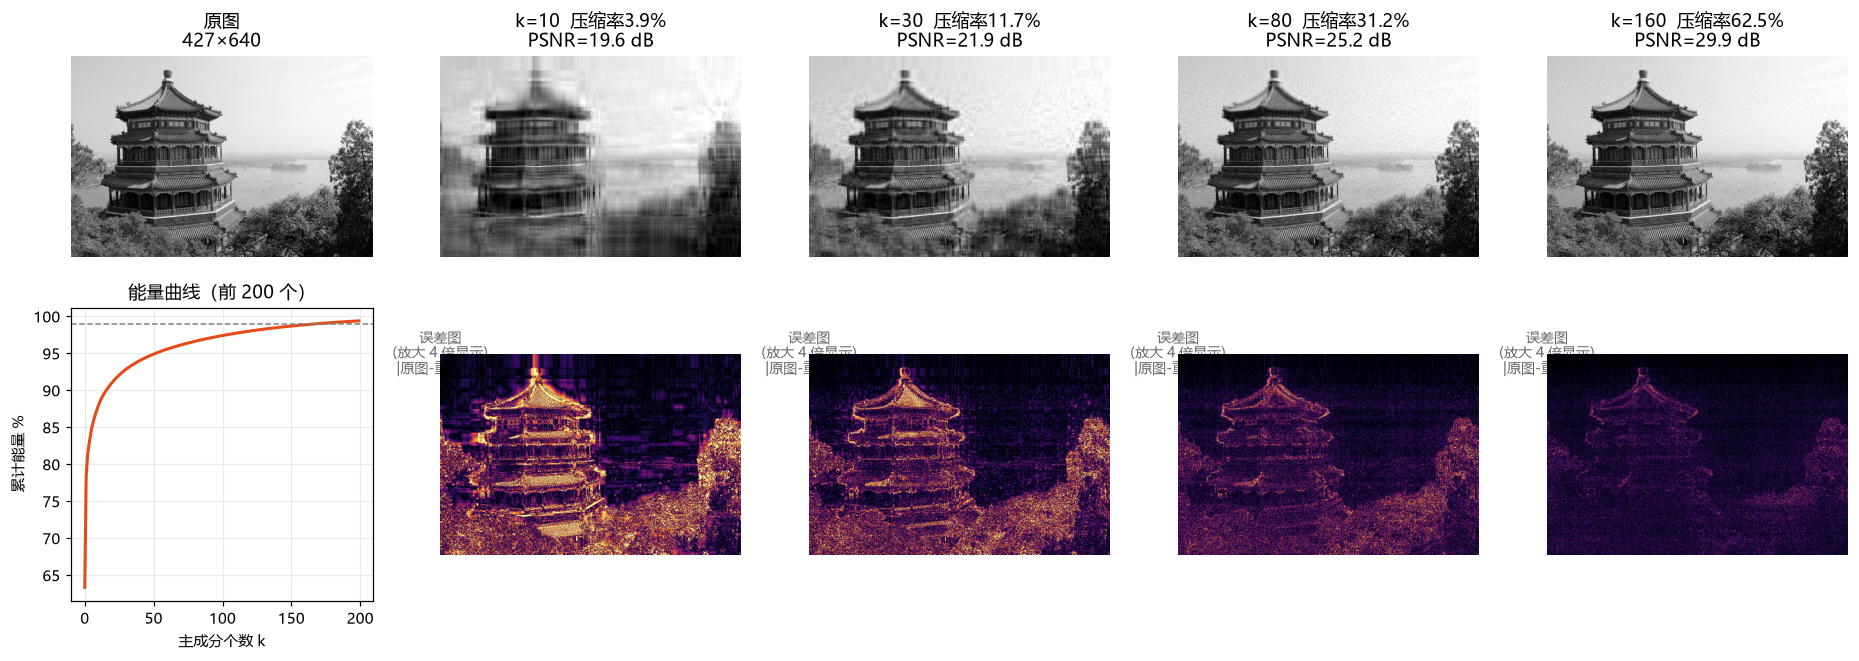

已保存 images/nb2_04_image_pca_k.png

观察：k 从 10 涨到 160，PSNR 提升明显；但能量 99% 时画面仍有细微模糊 ——
      说明「方差/能量」不是完美的视觉质量指标（人眼对边缘更敏感）。


In [13]:
# ---------- 11.3 不同 k / 不同保留比例下的质量与压缩率 ----------
import math

def psnr(a, b):
    '''峰值信噪比（a、b 都是 0~255 的灰度图，float 计算）'''
    mse = ((a.astype(np.float64) - b.astype(np.float64)) ** 2).mean()
    return float("inf") if mse == 0 else 10 * math.log10(255.0 ** 2 / mse)

# 一次性算好原图的全套特征值（复用，避免重复分解）
img_f = image.astype(np.float32)
img_c = img_f - img_f.mean(axis=0)
C_img = np.cov(img_c, rowvar=0)
evals, evecs = np.linalg.eigh(C_img)                 # 升序
evals, evecs = evals[::-1], evecs[:, ::-1]           # 转降序
cum_ratio = np.cumsum(evals) / evals.sum()

def recon_with_k(k):
    Pk = evecs[:, :k]
    Yk = img_c @ Pk
    Xk = Yk @ Pk.T + img_f.mean(axis=0)
    return np.clip(np.rint(Xk), 0, 255).astype(np.uint8)

print("k    | 压缩率   | 能量保留  | PSNR(dB)")
print("-" * 44)
for k in [5, 10, 20, 40, 80]:
    rec = recon_with_k(k)
    ratio = (rows + cols) * k / (rows * cols)
    print(f"{k:4d} | {ratio*100:7.1f}% | {cum_ratio[k-1]*100:8.2f}% | {psnr(image, rec):6.2f}")

print("\n不同「保留能量」目标 → 需要的 k：")
for p in (0.90, 0.95, 0.99, 0.995):
    k = int(np.searchsorted(cum_ratio, p) + 1)
    rec = recon_with_k(k)
    print(f"  保留 {p*100:5.1f}%  → k={k:3d}  压缩率={(rows+cols)*k/(rows*cols)*100:5.1f}%  PSNR={psnr(image, rec):5.2f} dB")

# ---------- 11.4 五联图：一眼看出 k 的影响 ----------
ks_show = [10, 30, 80, 160]
fig, axes = plt.subplots(2, len(ks_show) + 1, figsize=(17, 6.2))
axes[0, 0].imshow(image, cmap="gray")
axes[0, 0].set_title("原图\n%d×%d" % (rows, cols))
axes[0, 0].axis("off")
axes[1, 0].plot(cum_ratio[:200] * 100, lw=2, color="#E64A19")
axes[1, 0].set_xlabel("主成分个数 k"); axes[1, 0].set_ylabel("累计能量 %")
axes[1, 0].set_title("能量曲线（前 200 个）")
axes[1, 0].axhline(99, ls="--", lw=1, color="gray")

for i, k in enumerate(ks_show):
    rec = recon_with_k(k)
    ax = axes[0, i + 1]
    ax.imshow(rec, cmap="gray"); ax.axis("off")
    ax.set_title(f"k={k}  压缩率{(rows+cols)*k/(rows*cols)*100:.1f}%\nPSNR={psnr(image, rec):.1f} dB")
    axes[1, i + 1].axis("off")
    axes[1, i + 1].text(0.5, 0.5, f"误差图\n(放大 4 倍显示)\n|原图-重构|×4",
                        ha="center", va="center", fontsize=9, alpha=0.6)
    axes[1, i + 1].imshow(np.clip(np.abs(image.astype(int) - rec.astype(int)) * 4, 0, 255),
                          cmap="inferno")

plt.tight_layout()
plt.savefig("images/nb2_04_image_pca_k.png", dpi=140, bbox_inches="tight")
plt.show()
print("已保存 images/nb2_04_image_pca_k.png")
print("\n观察：k 从 10 涨到 160，PSNR 提升明显；但能量 99% 时画面仍有细微模糊 ——")
print("      说明「方差/能量」不是完美的视觉质量指标（人眼对边缘更敏感）。")

# 12. 综合范例 C：用 SVD 实现同一件事（为什么 sklearn 内部用 SVD）

## 数学关系

对**已中心化**的数据矩阵 $X_c$（形状 $n \times d$）做奇异值分解：

$$X_c = U S V^\top$$

则：

| SVD 的量 | 与 PCA 的关系 |
| --- | --- |
| 右奇异向量 $V$ 的列 | = 协方差矩阵的**特征向量**（主成分方向） |
| 奇异值 $s_i$ | = $\sqrt{\lambda_i (n-1)}$，即 $\lambda_i = s_i^2/(n-1)$ |
| 得分 $Y = U S$ 的前 k 列 | = PCA 投影结果 |

## 为什么 SVD 更好

| | 特征分解协方差矩阵 | SVD |
| --- | --- | --- |
| 需要构造的矩阵 | 协方差 $d\times d$（会引入一次数值误差） | 直接用 $X$ |
| 样本数 << 特征数时 | 要先算 $d\times d$（比如 640×640） | 可以用 `full_matrices=False` 只算前 min(n,d) 个 |
| 数值稳定性 | 一般 | **更好**（协方差会放大条件数） |
| 是否有符号歧义 | 有 | 有（同样有） |

sklearn 的 `PCA(svd_solver="full")` 走的正是 SVD 路线。

## 一行版 PCA

```python
U, S, Vt = np.linalg.svd(X - X.mean(0), full_matrices=False)
recon = (U[:, :k] * S[:k]) @ Vt[:k] + X.mean(0)
```

In [14]:
# ---------- 12.1 SVD 与特征分解的对应关系 ----------
from sklearn.datasets import load_iris
X = load_iris().data
mu = X.mean(axis=0)
Xc = X - mu

w_cov, V_cov = np.linalg.eigh(np.cov(Xc, rowvar=0))
w_cov, V_cov = w_cov[::-1], V_cov[:, ::-1]          # 降序

U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
print("SVD 奇异值 S         :", np.round(S, 4))
print("sqrt(λ·(n-1))        :", np.round(np.sqrt(w_cov * (Xc.shape[0] - 1)), 4))
print("两者一致             :", np.allclose(S, np.sqrt(w_cov * (Xc.shape[0] - 1))))

print("\n右奇异向量（Vt 的行）与协方差特征向量（列）一致（可能差符号）:",
      np.allclose(np.abs(Vt.T), np.abs(V_cov)))

k = 2
Y_svd = U[:, :k] * S[:k]                          # 得分 = U·S
Y_cov = Xc @ V_cov[:, :k]                         # 传统做法
print("\n两版得分一致（绝对值）:", np.allclose(np.abs(Y_svd), np.abs(Y_cov)))

recon_svd = (U[:, :k] * S[:k]) @ Vt[:k] + mu      # ← 一行版 PCA 重构
recon_cov = Y_cov @ V_cov[:, :k].T + mu
print("两版重构一致:", np.allclose(recon_svd, recon_cov))

# ---------- 12.2 速度对比（在 640×640 的图片数据上） ----------
img_c = image.astype(np.float64) - image.mean(axis=0)

t = time.perf_counter()
C_img = np.cov(img_c, rowvar=0)
_w, _V = np.linalg.eigh(C_img)
t_eigh = time.perf_counter() - t

t = time.perf_counter()
np.linalg.svd(img_c, full_matrices=False)
t_svd = time.perf_counter() - t

print(f"\n{[*img_c.shape]} 矩阵:")
print(f"  协方差 + eigh : {t_eigh*1000:7.1f} ms")
print(f"  SVD           : {t_svd*1000:7.1f} ms")
print("  （样本数远大于特征数时两者接近；样本数 << 特征数时 SVD 优势明显）")

# ---------- 12.3 三种写法算出的降维结果应一致 ----------
print("\n最终结论：手写特征分解、SVD、sklearn 三者结果一致（符号可能相反），")
print("工程上直接用 sklearn 即可，但自己写一遍才能理解每一步在做什么。")

SVD 奇异值 S         : [25.1     6.0131  3.4137  1.8845]
sqrt(λ·(n-1))        : [25.1     6.0131  3.4137  1.8845]
两者一致             : True

右奇异向量（Vt 的行）与协方差特征向量（列）一致（可能差符号）: True

两版得分一致（绝对值）: True
两版重构一致: True

[427, 640] 矩阵:
  协方差 + eigh :    80.5 ms
  SVD           :    69.9 ms
  （样本数远大于特征数时两者接近；样本数 << 特征数时 SVD 优势明显）

最终结论：手写特征分解、SVD、sklearn 三者结果一致（符号可能相反），
工程上直接用 sklearn 即可，但自己写一遍才能理解每一步在做什么。


# 13. 速查表

## 13.1 函数速查

| 函数 | 一句话作用 | 记忆点 |
| --- | --- | --- |
| `np.mean(x, axis=0)` | 每列均值 | `axis` = 「消掉哪一维」 |
| `np.tile(v, (n, 1))` | 把向量复制成 n 行 | 能用广播就别用它 |
| `np.cov(x, rowvar=0)` | 列是变量的协方差矩阵 | 数据是 (样本,特征) → `rowvar=0` |
| `np.corrcoef(x, rowvar=0)` | 相关系数矩阵 | 去量纲版协方差 |
| `np.linalg.eig(A)` | 一般方阵特征分解 | 特征向量**按列**、**无序**、可能有复数 |
| `np.linalg.eigh(A)` | 对称矩阵特征分解 | **升序**、实数、更快 |
| `np.linalg.eigvalsh(A)` | 只要特征值 | 更快 |
| `np.argsort(-x)` | 降序下标 | 取前 k 大 |
| `np.argpartition(x, -k)` | 前 k 大的下标（不排序） | 大数据集更快 |
| `np.searchsorted(cum, 0.99)` | 有序数组里找位置 | 一行替代 `Percentage2n` |
| `np.cumsum(x)` | 累计和 | 累计贡献率 |
| `A @ B` | 矩阵乘 | 永远优先用它 |
| `A * B` | 逐元素乘 | 不是矩阵乘！ |
| `np.clip(np.rint(x), 0, 255).astype(np.uint8)` | 安全转像素 | 别直接 `astype` |
| `np.allclose(a, b)` | 浮点比较 | 别用 `==` |
| `plt.subplots(r, c)` | 建网格子图 | 比 `add_subplot` 好用 |
| `ax.twinx()` | 双 y 轴 | 两种量纲同图 |
| `fig.savefig(p, bbox_inches="tight")` | 保存 | 要在 `show()` 之前 |
| `cv.cvtColor(img, cv.COLOR_BGR2GRAY)` | 转灰度 | OpenCV 用 BGR |
| `cv.imdecode(np.fromfile(p, np.uint8), 1)` | 读中文路径 | `imread` 对中文路径返回 None |

## 13.2 PCA 全流程速查

```python
mu  = X.mean(axis=0)                 # ① 均值
Xc  = X - mu                         # ② 中心化
C   = np.cov(Xc, rowvar=0)           # ③ 协方差
w,V = np.linalg.eigh(C)              # ④ 特征分解（升序）
idx = np.argsort(-w)                 # ⑤ 降序
w,V = w[idx], V[:, idx]
P   = V[:, :k]                       # ⑥ 前 k 个方向
Y   = Xc @ P                         # ⑦ 降维结果 (n,k)
X̂   = Y @ P.T + mu                   # ⑧ 重构
ratio = w / w.sum()                  # ⑨ 贡献率
```

# 14. 常见报错对照表

| 报错 / 现象 | 原因 | 解决 |
| --- | --- | --- |
| `AttributeError: module 'numpy' has no attribute 'mat'` | NumPy ≥ 2.0 移除了 `np.mat`/`np.matrix` | 用 `@` / `np.dot` |
| `ValueError: operands could not be broadcast together with shapes (150,4) (150,)` | `mean(axis=1)` 少了 `keepdims=True` | `X.mean(axis=1, keepdims=True)` |
| `ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0` | 矩阵乘法内维不等 | 检查 `(m,n)@(n,p)`，必要时 `.T` |
| `LinAlgError: Last 2 dimensions of the array must be square` | `eig`/`cov` 传了非方阵（比如 `rowvar` 写反得到 150×150 又用错） | 检查 `np.cov(..., rowvar=0)` |
| 特征值出现复数 | 矩阵不对称（数值误差或真的不对称） | 用 `eigh`，或 `np.real_if_close` |
| `IndexError: index 4 is out of bounds` | `k` 大于特征个数（原代码 `k=5` 而只有 4 个特征） | 限制 `k ≤ min(shape)` |
| PCA 结果和 sklearn 差一个负号 | 特征向量符号不唯一 | 比较 `np.abs()` 或 `np.corrcoef` |
| 图里中文是方块 | 没设中文字体 | `rcParams["font.sans-serif"] = ["Microsoft YaHei"]` |
| `plt.show()` 后图空白 | inline 后端已消费图，或 `savefig` 在 `show` 之后 | 先 `savefig` 再 `show` |
| `cv.imread` 返回 `None` | 路径错 / 中文路径 | 检查路径；中文路径用 `imdecode(np.fromfile(...))` |
| `cv2.error: ... The function is not implemented` | 无 GUI 环境调用 `cv.imshow` | notebook 里改用 `plt.imshow` |
| `astype(np.uint8)` 画面出现异常斑点 | 负数/超 255 回绕 | `np.clip(np.rint(x), 0, 255)` |
| 重构结果整体偏移很大 | 忘了把均值加回去 | `X̂ = Y Pᵀ + μ` |
| `Percentage2n` 返回 `None` | 传入的 `percentage > 1` | 参数限制在 `(0, 1]`，或加判断 |
| `MemoryError` / 极慢 | 用 `tile` 给百万级样本复制了均值矩阵 | 改用广播 |

## 最后

- 这份笔记里每个函数都对应 `01_鸢尾花PCA_注释版.ipynb` 里的一行代码，
  想不起某个参数时回原始代码看一眼；
- 想看交互式结果，打开同目录的 `03_iris_pca_可视化.html`。